# Telecom churn: who leaves, and how much revenue a targeted offer could protect

**Business question:** which customers are most likely to cancel, and if the company can only contact some of them with a retention offer, which ones should it contact?

**Data:** IBM Telco Customer Churn sample (via Kaggle), 7,043 customers of a fictional telecom provider. `Churn = Yes` means the customer left within the last month.

**Result:** 26.5% of customers left, taking 30.5% of monthly revenue. A logistic regression model (ROC AUC 0.85) ranks customers so that contacting the riskiest 20% reaches half of all leavers, against 20% with random selection.

## 1. Setup

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)

# One colour for the main data, grey for context, orange for the bar to notice
ACCENT, HIGHLIGHT, MUTED, INK_SOFT, GRID = "#2a78d6", "#eb6834", "#c9c8c3", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRID, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT})
SOURCE = "Source: IBM Telco Customer Churn sample data (Kaggle)"

## 2. Load and clean

In [3]:
df = pd.read_csv(DATA)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# TotalCharges is stored as text. Some values are blank: which customers are they?
blank = df["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum())
print("Their tenure (months):", df.loc[blank, "tenure"].unique())

Blank TotalCharges: 11
Their tenure (months): [0]


In [5]:
# Blank rows are brand-new customers (tenure 0) who have not been billed yet, so 0 is the correct value
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# A 1/0 churn column is easier to average and model than Yes/No
df["churned"] = (df["Churn"] == "Yes").astype(int)

print(df.dtypes.value_counts())
print("Missing values left:", df.isna().sum().sum())

object     17
int64       2
float64     2
int32       1
dtype: int64
Missing values left: 0


**What this shows:** *The data has 7,043 customers and 21 columns. TotalCharges was stored as text, and 11 values were blank. All 11 belong to customers with a tenure of 0 months, who had not yet been billed, so I set them to 0 rather than deleting them. No other values are missing.*

## 3. How many customers leave?

In [6]:
churn_rate = df["churned"].mean()
monthly_revenue = df["MonthlyCharges"].sum()
lost_revenue = df.loc[df["churned"] == 1, "MonthlyCharges"].sum()

print(f"Churn rate: {churn_rate:.1%}")
print(f"Monthly revenue, all customers: ${monthly_revenue:,.0f}")
print(f"Monthly revenue of customers who left: ${lost_revenue:,.0f} ({lost_revenue / monthly_revenue:.1%})")

Churn rate: 26.5%
Monthly revenue, all customers: $456,117
Monthly revenue of customers who left: $139,131 (30.5%)


## 4. Who leaves? Churn rate by customer group

In [7]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])

def churn_by(column):
    out = df.groupby(column, observed=True)["churned"].agg(customers="count", churn_rate="mean")
    out["churn_rate"] = (out["churn_rate"] * 100).round(1)
    return out.sort_values("churn_rate", ascending=False)

for col in ["Contract", "tenure_group", "InternetService", "PaymentMethod"]:
    print(churn_by(col), "\n")

                customers  churn_rate
Contract                             
Month-to-month       3875        42.7
One year             1473        11.3
Two year             1695         2.8 

              customers  churn_rate
tenure_group                       
0-12 months        2186        47.4
13-24 months       1024        28.7
25-48 months       1594        20.4
49-72 months       2239         9.5 

                 customers  churn_rate
InternetService                       
Fiber optic           3096        41.9
DSL                   2421        19.0
No                    1526         7.4 

                           customers  churn_rate
PaymentMethod                                   
Electronic check                2365        45.3
Mailed check                    1612        19.1
Bank transfer (automatic)       1544        16.7
Credit card (automatic)         1522        15.2 



In [8]:
# Are these differences real, or could they be chance? Chi-square test of independence.
# Gender is included as a comparison: we expect it NOT to matter.
rows = []
for col in ["Contract", "tenure_group", "InternetService", "PaymentMethod", "gender"]:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[col], df["churned"]))
    rows.append({"variable": col, "chi_square": round(chi2, 1), "p_value": p,
                 "significant_at_5pct": p < 0.05})
pd.DataFrame(rows)

,variable,chi_square,p_value,significant_at_5pct
0,Contract,1184.6,5.863038e-258,True
1,tenure_group,856.1,2.943770e-185,True
2,InternetService,732.3,9.571788e-160,True
3,PaymentMethod,648.1,3.682355e-140,True
4,gender,0.5,4.865787e-01,False


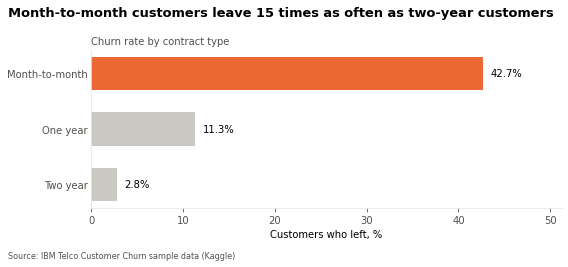

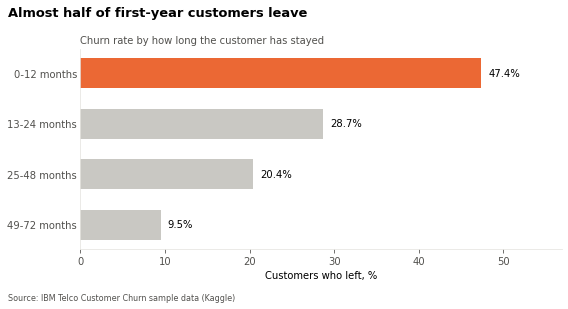

In [9]:
def bar_chart(table, title, subtitle, filename, highlight):
    table = table.iloc[::-1]  # largest at the top
    colours = [HIGHLIGHT if label == highlight else MUTED for label in table.index.astype(str)]
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(table) + 1.8))
    bars = ax.barh(table.index.astype(str), table["churn_rate"], color=colours, height=0.6)
    for bar, value in zip(bars, table["churn_rate"]):
        ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%", va="center")
    ax.set_xlim(0, table["churn_rate"].max() * 1.2)
    ax.set_xlabel("Customers who left, %")
    ax.tick_params(axis="y", length=0)
    ax.set_title(subtitle, loc="left", fontsize=10, color=INK_SOFT)
    fig.suptitle(title, x=0.02, ha="left", fontsize=13, fontweight="bold")
    fig.text(0.02, 0.01, SOURCE, fontsize=8, color=INK_SOFT)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(CHARTS / filename, dpi=200, facecolor="white")
    plt.show()

bar_chart(churn_by("Contract"), "Month-to-month customers leave 15 times as often as two-year customers",
          "Churn rate by contract type", "churn_by_contract.png", "Month-to-month")
bar_chart(churn_by("tenure_group"), "Almost half of first-year customers leave",
          "Churn rate by how long the customer has stayed", "churn_by_tenure.png", "0-12 months")

**What this shows:** *Month-to-month customers leave at 42.7%, about 15 times the rate of two-year customers (2.8%). Almost half of customers in their first year leave (47.4%), against 9.5% of those who have stayed over four years. Fibre optic customers (41.9%) and those paying by electronic check (45.3%) also leave more often. Chi-square tests show all four differences are statistically significant, while gender makes no difference (p = 0.49). These results show which groups leave more, not why they leave.*

## 5. Predict who will leave

The goal is a model that **ranks** customers by risk, so the company can contact the riskiest first.

- The data is split into a **training set (75%)** to build the model and a **test set (25%)** it never sees, to check it honestly.
- `stratify` keeps the same churn rate in both sets.
- **Logistic regression** is the simple, explainable baseline; **random forest** tests whether a more flexible model does better.
- **ROC AUC** measures ranking quality: 0.5 is a coin flip, 1.0 is perfect. It suits this problem because only about a quarter of customers churn, so plain accuracy would be misleading (a model that predicts "nobody leaves" is already 73% accurate).

In [10]:
features = df.drop(columns=["customerID", "Churn", "churned", "tenure_group"])
X = pd.get_dummies(features, drop_first=True).astype(float)
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("Training:", X_train.shape, " Test:", X_test.shape)
print(f"Churn rate, training: {y_train.mean():.1%}   test: {y_test.mean():.1%}")

Training: (5282, 30)  Test: (1761, 30)
Churn rate, training: 26.5%   test: 26.5%


In [11]:
# Logistic regression works best when numeric columns are on a similar scale
numeric = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler().fit(X_train[numeric])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[numeric] = scaler.transform(X_train[numeric])
X_test_s[numeric] = scaler.transform(X_test[numeric])

logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
p_logreg = logreg.predict_proba(X_test_s)[:, 1]

forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42).fit(X_train, y_train)
p_forest = forest.predict_proba(X_test)[:, 1]

print(f"ROC AUC, logistic regression: {roc_auc_score(y_test, p_logreg):.3f}")
print(f"ROC AUC, random forest:       {roc_auc_score(y_test, p_forest):.3f}")

ROC AUC, logistic regression: 0.847
ROC AUC, random forest:       0.845


In [12]:
# Precision: of the customers flagged as leaving, how many actually left?
# Recall: of the customers who actually left, how many were flagged?
print(classification_report(y_test, (p_logreg >= 0.5).astype(int), target_names=["Stayed", "Left"]))

              precision    recall  f1-score   support

      Stayed       0.85      0.90      0.87      1294
        Left       0.66      0.55      0.60       467

    accuracy                           0.81      1761
   macro avg       0.75      0.73      0.74      1761
weighted avg       0.80      0.81      0.80      1761



**What this shows:** *Both models rank customers well: logistic regression scores a ROC AUC of 0.847 and the random forest 0.845, where 0.5 would be random guessing. I chose logistic regression because it performs just as well and is simpler to explain to a business. Accuracy alone would be misleading here, since a model predicting that nobody leaves would already be 73% accurate.*

## 6. Who should get the retention offer?

Sort the test customers from highest to lowest predicted risk. If the company contacts only the top 10%, 20% or 30%, how many of the customers who actually left would it reach?

In [13]:
test = pd.DataFrame({"risk": p_logreg, "left": y_test.values,
                     "monthly_charges": df.loc[X_test.index, "MonthlyCharges"].values})
test = test.sort_values("risk", ascending=False).reset_index(drop=True)

total_left = test["left"].sum()
revenue_left = test.loc[test["left"] == 1, "monthly_charges"].sum()

rows = []
for share in [0.10, 0.20, 0.30]:
    top = test.head(int(round(len(test) * share)))
    rows.append({
        "customers_contacted": f"Top {share:.0%} ({len(top)})",
        "leavers_reached": int(top["left"].sum()),
        "share_of_all_leavers": f"{top['left'].sum() / total_left:.0%}",
        "hit_rate": f"{top['left'].mean():.0%}",
        "share_of_lost_revenue": f"{top.loc[top['left'] == 1, 'monthly_charges'].sum() / revenue_left:.0%}",
    })
print(f"Test set: {len(test)} customers, {total_left} left ({test['left'].mean():.1%})")
pd.DataFrame(rows)

Test set: 1761 customers, 467 left (26.5%)


,customers_contacted,leavers_reached,share_of_all_leavers,hit_rate,share_of_lost_revenue
0,Top 10% (176),130,28%,74%,31%
1,Top 20% (352),235,50%,67%,55%
2,Top 30% (528),309,66%,59%,70%


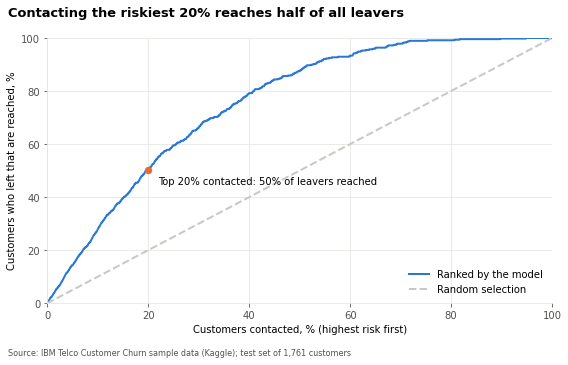

In [14]:
# Cumulative gains chart: how quickly the model finds leavers compared with contacting customers at random
contacted = np.arange(1, len(test) + 1) / len(test) * 100
found = test["left"].cumsum() / total_left * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(contacted, found, color=ACCENT, linewidth=2, label="Ranked by the model")
ax.plot([0, 100], [0, 100], color=MUTED, linewidth=2, linestyle="--", label="Random selection")
i = int(round(len(test) * 0.2)) - 1
ax.scatter(contacted[i], found.iloc[i], color=HIGHLIGHT, zorder=3, s=40)
ax.annotate(f"Top 20% contacted: {found.iloc[i]:.0f}% of leavers reached",
            (contacted[i], found.iloc[i]), xytext=(10, -15), textcoords="offset points")
ax.set_xlabel("Customers contacted, % (highest risk first)")
ax.set_ylabel("Customers who left that are reached, %")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(color=GRID)
ax.legend(frameon=False, loc="lower right")
fig.suptitle("Contacting the riskiest 20% reaches half of all leavers", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.02, 0.01, SOURCE + "; test set of 1,761 customers", fontsize=8, color=INK_SOFT)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / "gains_curve.png", dpi=200, facecolor="white")
plt.show()

**What this shows:** *Contacting the 20% of customers the model rates riskiest reaches 235 of the 467 customers who left (50%), against 20% if customers were picked at random. Two out of three customers contacted (67%) were actual leavers, compared with about one in four overall. This group also accounts for 55% of the monthly revenue lost to churn.*

## 7. Recommendation

*Use the model to choose who receives a retention offer each month, starting with the riskiest 20% of customers.*

*Focus offers on month-to-month customers, for example a discount for switching to a one- or two-year contract, since contract customers leave far less often.*

*Give extra attention to customers in their first year, when almost half of leavers go.*

*Test the offer before rolling it out: give it to half of the high-risk group, and compare how many stay against the half that did not receive it.*

## 8. Limitations

*The data is a sample from a fictional company, covering a single month of churn, so results may differ for a real provider.*

*The analysis shows which customers are likely to leave, not why. Whether an offer would keep them can only be shown by a test.*

*Lost revenue is measured as the leavers’ monthly charges, not their full lifetime value.*